# 08 — What is Anthropic worth per share, on today's share count?

**Question:** 06 gives 20,000 simulated paths for revenue and owner free cash flow to 2030. What are those cash flows worth today, per share, and how does that compare with what investors have paid and the **$83 IPO price** (Nov 18, above the $70–78 range)?

**Short answer**
1. **Discount rate ~10.5%:** the Treasury rate (4.94%) plus listed software's beta (1.25) times the market's equity risk premium (4.41%). There's no debt to blend in: the convertible notes become shares. The risk of failure is already in 06's bad worlds, so we don't add a venture-style premium on top (§1).
2. 06 stops in 2030, with most worlds still growing ~20% a year. We extend each world on its own Gompertz curve to 2040, then add a perpetuity growing 3%. By 2040 the median world does ~$1.3T of revenue at a **~10% owner FCF margin**. That thin margin comes straight from 06's cost structure: compute takes 40–67% of revenue and opex stays at 25% (§2).
3. On today's ~16.4B fully diluted shares, the **median world is worth ~$59 a share (~$970B)**, P10–P90 **$10–143**. The **average is ~$69**: a few very large worlds pull it above the median, and it's the fair value the blog uses because it counts them. That's above Series G ($25.91) and right at Series H ($58.90), but below the company's own Sep-30 mark on Amazon's notes (~$71), the $70–78 range and the **$83 IPO price** ($1.36T on today's shares). **~33% of worlds** are worth $83. By its own compute contracts alone, Anthropic is worth **~$18–45** (09 §6). **~4% of worlds are worth $0**: worlds where Anthropic earns less than ~$1.56 of revenue per compute dollar (Q3-2026: $1.72) lose cash on every extra dollar of revenue, so the bigger they get the worse it is (§3, `08_value_per_share.png`).
4. **74% of the median world's value arrives after 2030**, and 40% after 2040. Cash is ~$8 a share. Value depends more on **efficiency** (revenue per compute dollar) than on the **ceiling**: with a mid-sized ceiling, going from low to high efficiency takes the value from ~$23 to ~$99 (§4, `08_value_sources.png`).
5. The discount rate moves the median between **~$44 (13%) and ~$68 (9.5%)**, and terminal growth of 2–4% only moves it $56–63. The biggest dial is the cost structure: if opex falls to 20% of revenue by 2040, the median is **~$74**; at 15% it's **~$90**, above the IPO price (§5).
6. **Reverse DCF:** buying at $83 and getting the median world earns ~**8.3% a year**, against the 10.5% CAPM asks. The worlds that justify $83 have a ~$880B ceiling (vs ~$440B), ~$720B of 2030 revenue (vs ~$430B), ~$2.0T of 2040 revenue and 2.26x revenue per compute dollar (vs 1.85x). The IPO price buys a top-third outcome. Cross-check: the company's ~$81B October run-rate sits at 06's P18, so with the 30–55% share range the forecast starts on the high side (§6).

| § | Question | Chart |
|---|---|---|
| 1 | What discount rate? | — |
| 2 | What happens after 2030? | — |
| 3 | What is each world worth per share? | `08_value_per_share.png` |
| 4 | Where does the value come from? | `08_value_sources.png` |
| 5 | How sensitive is it to the rate, terminal growth and cost structure? | — |
| 6 | What is the IPO price betting on? | — |

**Scope: today's share count only.** Every per-share number divides by the ~16.4B fully diluted shares from 04 (common, preferred as converted, Amazon notes, Public Benefit Fund, options, RSUs). The IPO's new shares and its cash are both left out, and so are the Public Benefit Fund's top-ups after the IPO. Future grants and share-paid donations stay in as costs (3% + 4% of revenue). 09 §7 prices what those costs take per share (~$36) and adds the top-ups as shares (~1%).

**Inputs:** `data/forecast_worlds.csv` (06, every simulated world), `data/compute_schedule.csv` (03), `data/kpis.csv`, `data/dilution.csv` (04), `data/stock_options.csv`, `data/balance_sheet.csv`, `data/preferred_stock.csv`, `data/convertible_notes_outstanding.csv`.
**Outputs:** `data/valuation_inputs.csv` (outside data: rates, ERP, betas, IPO terms, each with `as_of`, `source_url`, `reliability`); `data/valuation.csv` (P10–P90 and the mean of each value component and value per share).

**How to read this notebook.** Data are in $ millions; charts and prose are in $ billions, and per-share figures in dollars. The valuation date is **2026-09-30**, the balance-sheet date, so cash and shares match. Every assumption lives in the `V` dict (valuation) and `A` dict (costs after 2030, same values as 06's `A`) in the next cell.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import *

B = 1000                                                              # $M -> $B
K = load('kpis').drop_duplicates('metric').set_index('metric').value
W = pd.read_csv(DATA / 'forecast_worlds.csv', index_col='world')     # 06: one row per simulated world
commit = load('compute_schedule').set_index('year').sum(axis=1)       # 03: committed compute by year, $M
bs = wide(load('balance_sheet'))['2026-09-30']

# Outside data, not from the S-1 (kept out of the reconciliation checks)
OUTSIDE = [  # (item, value, unit, as_of, source_url, reliability, note)
    ('risk_free_rate', 4.94, 'pct', '2026-11-01', 'https://pages.stern.nyu.edu/~adamodar/New_Home_Page/home.htm', 'primary',
     'US T-bond rate Damodaran uses with his Nov-1 implied ERP; 10y Treasury closed 4.86% on Nov 6 (Advisor Perspectives)'),
    ('equity_risk_premium', 4.41, 'pct', '2026-11-01', 'https://pages.stern.nyu.edu/~adamodar/New_Home_Page/home.htm', 'primary',
     'Damodaran implied ERP, S&P 500, trailing 12m with adjusted payout; variants 3.39%-5.81%'),
    ('beta_software_system_app', 1.25, 'x', '2026-01-01', 'https://pages.stern.nyu.edu/~adamodar/New_Home_Page/datafile/Betas.html', 'primary',
     'Damodaran, Software (System & Application), 309 firms, unlevered beta corrected for cash'),
    ('beta_software_internet', 1.59, 'x', '2026-01-01', 'https://pages.stern.nyu.edu/~adamodar/New_Home_Page/datafile/Betas.html', 'primary',
     'Damodaran, Software (Internet), 29 firms, unlevered beta corrected for cash'),
    ('beta_semiconductor', 1.50, 'x', '2026-01-01', 'https://pages.stern.nyu.edu/~adamodar/New_Home_Page/datafile/Betas.html', 'primary',
     'Damodaran, Semiconductor, 66 firms, unlevered beta corrected for cash'),
    # S-1/A No. 2 (filed 2026-11-10): the marketed range
    ('ipo_price_low', 70.0, 'usd_per_share', '2026-11-10', 'https://www.sec.gov/Archives/edgar/data/2130357/000162828026072484/anthropicpbc-sx1ax2.htm', 'primary', 'cover: "between $70.00 and $78.00"'),
    ('ipo_price_high', 78.0, 'usd_per_share', '2026-11-10', 'https://www.sec.gov/Archives/edgar/data/2130357/000162828026072484/anthropicpbc-sx1ax2.htm', 'primary', 'idem'),
    # Final prospectus (424B4, filed 2026-11-19, cached as source_docs/anthropic_424b4.htm; 01 extracts its financials)
    ('ipo_price', 83.0, 'usd_per_share', '2026-11-18', 'https://www.sec.gov/Archives/edgar/data/2130357/000162828026074944/anthropicpbc-424b4.htm', 'primary', 'cover: "Initial public offering price $83.00", above the $70-78 range'),
    ('ipo_shares_offered_company', 956.351354, 'millions_shares', '2026-11-18', 'https://www.sec.gov/Archives/edgar/data/2130357/000162828026074944/anthropicpbc-424b4.htm', 'primary', 'Class A offered by us'),
    ('ipo_shares_offered_selling_holders', 23.648646, 'millions_shares', '2026-11-18', 'https://www.sec.gov/Archives/edgar/data/2130357/000162828026074944/anthropicpbc-424b4.htm', 'primary', 'no proceeds to the company; already in the fully diluted count'),
    ('ipo_underwriter_option', 147.0, 'millions_shares', '2026-11-18', 'https://www.sec.gov/Archives/edgar/data/2130357/000162828026074944/anthropicpbc-424b4.htm', 'primary', 'option to purchase additional Class A from us, 30 days'),
    ('ipo_private_placement', 26000.0, 'millions_usd', '2026-11-18', 'https://www.sec.gov/Archives/edgar/data/2130357/000162828026074944/anthropicpbc-424b4.htm', 'primary',
     'Class N at $83, 313,253,007 shares: Google $10B, NVIDIA $10B, AMD $2.5B, Broadcom/Micron/Microsoft $1B each, TSMC $0.5B'),
    ('ipo_net_proceeds', 104800.0, 'millions_usd', '2026-11-18', 'https://www.sec.gov/Archives/edgar/data/2130357/000162828026074944/anthropicpbc-424b4.htm', 'primary', 'offering + placement, no option exercise ($117.0B with it)'),
    ('ipo_shares_outstanding_after', 13219.642276, 'millions_shares', '2026-11-18', 'https://www.sec.gov/Archives/edgar/data/2130357/000162828026074944/anthropicpbc-424b4.htm', 'primary', 'Class A + N (+T, F) outstanding after the offering and placement, no option'),
    ('ant_first_trade', 111.5, 'usd_per_share', '2026-11-19', 'https://www.cnn.com/2026/11/19/business/live-news/anthropic-ipo', 'press',
     'Nasdaq: ANT opening trade, 34% above $83; high $115.10, ~$95-100 by midday (Forbes, NBC)'),
    ('ipo_valuation_top', 1.4e6, 'millions_usd', '2026-11-10', 'https://aljazeera.com/economy/2026/11/10/anthropic-targets-1-4-trillion-valuation-in-massive-stock-market-debut', 'press',
     '"up to $1.4 trillion when potential shares are included"'),
    ('run_rate_revenue_oct2026', 81000.0, 'millions_usd', '2026-11-12', 'https://www.sec.gov/Archives/edgar/data/2130357/000162828026072949/anthropicpbc-fwpipowebsi.htm', 'primary',
     'FWP (IPO website): "~$81B Run-Rate Revenue as of October 2026"; company definition, not net of policy violators'),
]
X = pd.DataFrame(OUTSIDE, columns=['item', 'value', 'unit', 'as_of', 'source_url', 'reliability', 'note'])
X.to_csv(DATA / 'valuation_inputs.csv', index=False)
x = X.set_index('item').value

# --- Valuation assumptions (explained in §1-§2) ---
V = dict(risk_free=x['risk_free_rate'] / 100, erp=x['equity_risk_premium'] / 100,
         beta=x['beta_software_system_app'],              # base; internet software's 1.59 is the high case
         terminal_growth=0.03,                              # after 2040, forever; below the risk-free rate
         last_year=2040,                                    # extend each world's curve to here, then a perpetuity
         opex_end=0.25)                                     # cash opex % of revenue reached by 2040 (0.25 = no scale leverage)
# --- Costs after 2030: same values as 06's A (see 03 for the reasoning) ---
A = dict(cash_opex_pct=0.25, sbc_new_grants_pct=0.04, donations_pct=0.03, capex_pct=0.04, tax_rate=0.21,
         ceiling_growth=K['it_spend_cagr_2006_2025'] / 100)

## 1. What discount rate?
**Why ask:** a dollar of free cash flow in 2035 is worth less than a dollar today, both because money earns interest and because investors want paying for the risk. The discount rate sets that exchange rate, and with most of the value years away, it moves the answer a lot.

**Method: the capital asset pricing model (CAPM),** the textbook way to price equity risk:
$$r = r_f + \beta \times \text{ERP}$$
- $r_f$, the **risk-free rate**: what a US Treasury bond pays, **4.94%** (the rate Damodaran pairs with his Nov 1 ERP; the 10-year closed at 4.86% on Nov 6).
- **ERP**, the **equity risk premium**: the extra return the stock market as a whole is priced to deliver above Treasuries. Damodaran backs it out of S&P 500 prices and expected cash payouts each month: **4.41%** on Nov 1, 2026.
- $\beta$, **beta**: how much a stock swings with the market. 1.0 is market risk. Anthropic has no trading history, so we borrow the average for listed software companies, **1.25** (309 firms, Damodaran). Internet software (1.59) and semiconductors (1.50) are the high cases in §5.

**Why only the cost of equity, not a "WACC"?** A weighted-average cost of capital blends in the cost of debt. Anthropic has none that stays debt: the $130.5B of convertible notes converts into shares (they're in the 16.4B), and the finance leases on Broadcom chips are already in the compute bill as cash costs. Counting them as debt as well would charge for them twice.

**Why CAPM and not a venture-style 20–30%?** Venture rates bundle in the chance of failure. Here, that risk already sits in the cash flows: the bottom of 06's 20,000 worlds includes revenue that stalls under the take-or-pay compute bill. CAPM charges only for the risk you can't diversify away. Adding a failure premium on top would count the bad worlds twice.

In [2]:
r = V['risk_free'] + V['beta'] * V['erp']
r_high = V['risk_free'] + x['beta_software_internet'] * V['erp']
print(f"Discount rate: {V['risk_free']:.2%} + {V['beta']} x {V['erp']:.2%} = {r:.2%}  (internet-software beta: {r_high:.2%})")

Discount rate: 4.94% + 1.25 x 4.41% = 10.45%  (internet-software beta: 11.95%)


**What this shows:** a base discount rate of **~10.5%**, with ~11.9% at internet-software risk. For scale, that's about what investors require of the average large software stock today. Anthropic gets no discount for being young, and none for being the AI name everyone wants either.

**Next:** 06 stops in 2030, when most worlds are still growing fast. What comes after?

## 2. What happens after 2030?
**Why ask:** in 06's median world, revenue is still growing ~20% a year in 2030 and the margin is still rising. Cut the valuation off there and you miss most of the business. So we need a **terminal value**: one number standing for every cash flow after the forecast ends.

**Method, in two steps.**
1. **2031–2040: keep each world on its own curve.** Same Gompertz rule as 06 §1, with the same ceiling, speed and ceiling growth (7% a year), quarter by quarter from that world's Q4-2030 run-rate. Same costs as 06: compute is the larger of the take-or-pay schedule (03, which runs out in 2037) and revenue ÷ that world's revenue per compute dollar. Cash opex is 25%, new stock comp 4%, donations 3%, capex 4%, tax 21% on profits. By 2040 most worlds are close to their ceiling and growing at about the ceiling's 7%.
2. **After 2040: a growing perpetuity** (the Gordon formula). If cash flow next year is $CF_{2041}$ and it grows at $g$ forever, its value one year earlier is
$$TV_{2040} = \frac{CF_{2040}\,(1+g)}{r - g}$$
With $r$ = 10.5% and $g$ = 3%, that's ~14x 2040 cash flow. We pick $g$ = **3%**, below the risk-free rate. No company can outgrow the economy forever, and a perpetuity growing faster than $r$ has no finite value.

**Cash flows we value:** 06's **owner FCF** (real operating income − tax − capex; stock comp and donations counted as costs), with one change. **Stock comp on grants already made is added back.** Those RSUs and options are in the 16.4B share count already, so charging their $34B of expense as well would count the same dilution twice. Grants made after today, and share-paid donations, stay as costs: they're the shares not in the count.

**Timing:** each year's cash flow arrives mid-year. Q4-2026 counts as 0.125 years from Sep 30, 2027 as 0.75 years, and so on.

In [3]:
# Stock comp on grants already in the share count (same split as 06/03: catch-up at the IPO, the rest over 2027-29)
backlog = K['rsu_unrecognized_sbc'] - K['rsu_sbc_catchup_at_ipo'] + K['option_unrecognized_sbc']
Y1 = ['Q4-2026', '2027', '2028', '2029', '2030']
sbc_existing = pd.Series([K['rsu_sbc_catchup_at_ipo'], backlog / 3, backlog / 3, backlog / 3, 0.0], index=Y1)
cf_to_2030 = W[[f'owner_fcf_{y}' for y in Y1]].set_axis(Y1, axis=1) + sbc_existing

# 2031-2040: continue each world's Gompertz curve (06 §1). In 06, quarter t=1 is Q4-2026, so Q4-2030 is t=17.
Y2 = list(range(2031, V['last_year'] + 1))
run_rate, rev = W.run_rate_q4_2030.values, np.zeros((len(W), len(Y2)))
for i, t in enumerate(range(18, 18 + 4 * len(Y2))):
    ceiling_now = W.ceiling.values * (1 + A['ceiling_growth']) ** (t / 4)
    run_rate = run_rate * np.exp(W.speed.values * np.log(ceiling_now / run_rate))   # close `speed` of the log gap
    rev[:, i // 4] += run_rate / 4                                                   # a year's revenue = mean run-rate
rev_late = pd.DataFrame(rev, index=W.index, columns=Y2)

def cf_after_2030(opex_end):
    """Owner FCF 2031-2040 per world, with cash opex moving in a straight line from 25% to `opex_end` by 2040."""
    opex = pd.Series(np.linspace(A['cash_opex_pct'], opex_end, len(Y2) + 1)[1:], index=Y2)
    compute = rev_late.div(W.rev_per_compute, axis=0).clip(lower=commit.reindex(Y2, fill_value=0), axis=1)
    oi = rev_late.mul(1 - opex, axis=1) - compute - (A['sbc_new_grants_pct'] + A['donations_pct']) * rev_late
    return oi - A['tax_rate'] * oi.clip(lower=0) - A['capex_pct'] * rev_late

cf_late = cf_after_2030(V['opex_end'])
growth_2040 = rev_late[2040] / rev_late[2039] - 1
margin_2040 = cf_late[2040] / rev_late[2040]
pd.DataFrame({'revenue 2030, $B': W.revenue_2030 / B, 'revenue 2040, $B': rev_late[2040] / B,
              'growth in 2040': growth_2040, 'owner FCF margin 2040': margin_2040}
            ).quantile([0.1, 0.5, 0.9]).rename(index=lambda q: f'P{q*100:.0f}').round(2)

,"revenue 2030, $B","revenue 2040, $B",growth in 2040,owner FCF margin 2040
P10,305.62,682.04,0.07,0.00
P50,524.11,1307.62,0.07,0.10
P90,907.31,2592.99,0.07,0.17


**What this shows:** by 2040 the median world does **~$1.3T** of revenue, growing ~7% a year (the ceiling's own growth), with an owner FCF margin of **~10%**. That margin is low for a software company, and it comes straight from 06's cost structure. Compute alone takes 1 ÷ (revenue per compute dollar), 40–67% of revenue, and opex stays at 25% even at $1.3T of revenue. The 2040 margin is the single biggest lever on the terminal value, so §5 tests what happens if opex scales down.

**Next:** put it together, world by world.

## 3. What is each world worth per share?
**Method:** for each of the 20,000 worlds:
$$\text{Equity value} = \underbrace{\sum_{t} \frac{CF_t}{(1+r)^{t}}}_{\text{PV of 2026–2040 cash flows}} + \underbrace{\frac{TV_{2040}}{(1+r)^{t_{2040}}}}_{\text{PV of everything after}} + \text{cash} + \text{option strike proceeds}$$
- **Cash:** $131.8B of cash and short-term investments at Sep 30 (restricted cash left out). 06's owner FCF excludes interest income, so the pile is counted once, here, at face value.
- **Option strike proceeds:** the 16.4B count includes 1.77B options as if exercised. Holders pay the strike price ($2.91 average) to exercise, which brings in ~$5B.
- **No debt to subtract** (§1). The IPO's shares and cash are both out of scope.
- **Per share** = equity value ÷ 16.4B fully diluted shares (04).
- **Floor at zero.** In ~4% of worlds the cash flows stay negative forever and the sum comes out below zero. Shareholders can't lose more than the company is worth, so those worlds are worth $0 (in practice the company would restructure first). Who they are is explained below the chart.

**What to compare it with** (all from the S-1, per post-split common share): Series G at **$25.91** (March 2026; the April 2026 tender offer paid the same $25.91), Series H at **$58.90** (May–June 2026), and the company's own Sep 30 mark on Amazon's convertible notes: $130.5B fair value ÷ 1.84B shares on conversion ≈ **$71**. Plus the IPO range, **$70–78** (S-1/A No. 2, filed Nov 10).

In [4]:
fd_shares = load('dilution').query("scenario == 'today'").shares_k.sum() * 1e3      # 04: ~16.4B
opt = load('stock_options').set_index('event').loc['Balance as of September 30, 2026']
strike_proceeds = opt.shares_k * 1e3 * opt.wavg_exercise_price_usd / 1e6            # $M
cash = bs[['Cash and cash equivalents', 'Short-term investments']].sum()

t1 = pd.Series([0.125, 0.75, 1.75, 2.75, 3.75], index=Y1)                           # years from 2026-09-30, mid-period
t2 = pd.Series([y + 0.5 - 2026.75 for y in Y2], index=Y2)

def value(r, g, cf_late=cf_late):
    """Value of every world at discount rate r and terminal growth g. $M, plus $ per share."""
    pv_2030 = (cf_to_2030 / (1 + r) ** t1).sum(axis=1)
    pv_2040 = (cf_late / (1 + r) ** t2).sum(axis=1)
    terminal = cf_late[Y2[-1]] * (1 + g) / (r - g) / (1 + r) ** t2[Y2[-1]]
    v = pd.DataFrame({'pv_2026_2030': pv_2030, 'pv_2031_2040': pv_2040, 'terminal': terminal,
                      'cash_and_strikes': cash + strike_proceeds})
    v['equity'] = v.sum(axis=1).clip(lower=0)   # limited liability: shareholders can't be worth less than zero
    v['per_share'] = v.equity * 1e6 / fd_shares
    return v

val = value(r, V['terminal_growth'])
pref = load('preferred_stock').query("as_of == '2026-09-30'").set_index('series').issue_price_per_common_usd
notes = load('convertible_notes_outstanding')
MARKS = {  # $ per common share
    'Series G (Mar 2026)': pref['Series G-1'],
    'Series H (May-Jun 2026)': pref['Series H-1'],
    'Notes mark (Sep 30)': bs['Convertible notes payable'] * 1e6 / notes['Class N Shares Issuable on Conversion'].sum(),
}
ipo = (x['ipo_price_low'], x['ipo_price_high'])
ipo_price = x['ipo_price']
print(f'Fully diluted shares {fd_shares/1e9:.2f}B; cash ${cash/B:.1f}B; option strikes ${strike_proceeds/B:.1f}B')
print(f'Worlds floored at zero (cash flows negative forever): {(val.equity == 0).mean():.1%}')
for name, p in {**MARKS, 'IPO range low': ipo[0], 'IPO range high': ipo[1], 'IPO price': ipo_price}.items():
    print(f'{name:26s} ${p:6.2f}/share = ${p * fd_shares / 1e9:,.0f}B; worlds worth more: {(val.per_share > p).mean():.0%}')
PCTS = [0.10, 0.25, 0.50, 0.75, 0.90]
val_pct = val.quantile(PCTS).rename(index=lambda q: f'P{q*100:.0f}')
val_pct.assign(**{c: val_pct[c] / B for c in val_pct.columns if c != 'per_share'}).round(1)

Fully diluted shares 16.38B; cash $131.8B; option strikes $5.2B
Worlds floored at zero (cash flows negative forever): 3.8%
Series G (Mar 2026)        $ 25.91/share = $424B; worlds worth more: 80%
Series H (May-Jun 2026)    $ 58.90/share = $965B; worlds worth more: 50%
Notes mark (Sep 30)        $ 70.91/share = $1,161B; worlds worth more: 41%
IPO range low              $ 70.00/share = $1,146B; worlds worth more: 41%
IPO range high             $ 78.00/share = $1,277B; worlds worth more: 36%
IPO price                  $ 83.00/share = $1,359B; worlds worth more: 33%


,pv_2026_2030,pv_2031_2040,terminal,cash_and_strikes,equity,per_share
P10,1.0,11.8,14.6,137.0,168.7,10.3
P25,37.8,153.9,189.5,137.0,520.1,31.8
P50,91.6,332.8,408.6,137.0,967.9,59.1
P75,155.4,583.3,725.2,137.0,1602.7,97.9
P90,217.5,880.7,1108.5,137.0,2342.3,143.0


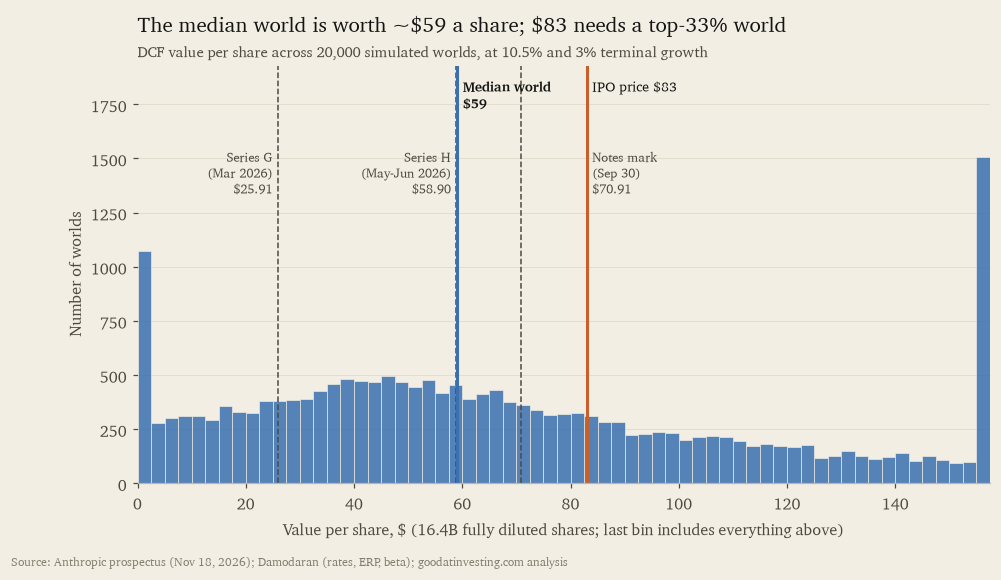

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.2))
bins = np.arange(0, 160, 2.5)
ax.hist(val.per_share.clip(upper=bins[-1] - 0.01), bins=bins, color=SERIES[0], alpha=0.85, edgecolor=SURFACE, lw=0.5)
ax.axvline(ipo_price, color=SERIES[1], lw=2)
top = ax.get_ylim()[1] * 1.22
ax.set_ylim(0, top)
ax.text(ipo_price + 1, top * 0.97, f'IPO price ${ipo_price:.0f}', ha='left', va='top', fontsize=9, color=INK)
for (name, p), (xpos, ha, ypos) in zip(MARKS.items(), ((None, 'right', 0.80), (None, 'right', 0.80), (ipo_price + 1, 'left', 0.80))):
    ax.axvline(p, color=INK2, ls='--', lw=1)
    ax.text(xpos or p - 1, top * ypos, f"{name.replace(' (', chr(10) + '(')}\n${p:.2f}", ha=ha, va='top', fontsize=8.5, color=INK2)
med = val.per_share.median()
ax.axvline(med, color=SERIES[0], lw=2)
ax.text(med + 1, top * 0.97, f'Median world\n${med:.0f}', va='top', fontsize=9, fontweight='bold', color=INK)
ax.set_xlim(0, bins[-1])
ax.set_xlabel('Value per share, $ (16.4B fully diluted shares; last bin includes everything above)')
ax.set_ylabel('Number of worlds')
ax.set_title(f'The median world is worth ~${med:.0f} a share; ${ipo_price:.0f} needs a top-{(val.per_share >= ipo_price).mean():.0%} world')
subtitle(ax, f'DCF value per share across {len(val):,} simulated worlds, at {r:.1%} and {V["terminal_growth"]:.0%} terminal growth')
source(fig, 'Source: Anthropic prospectus (Nov 18, 2026); Damodaran (rates, ERP, beta); goodatinvesting.com analysis')
fig.subplots_adjust(bottom=0.15)
save(fig, '08_value_per_share.png')
plt.show()

**What this shows** (`08_value_per_share.png`): the spread is wide and skewed right, which is typical when value is a long-dated bet on a ceiling nobody can measure.
- **Median ~$59, P25–P75 ~$32–98, P10–P90 ~$10–143.**
- **Series G ($25.91, Mar 2026)** is below 80% of worlds. On these cash flows, the March round looks cheap.
- **Series H ($58.90, May–Jun 2026)** is ~$965B on today's 16.4B shares, which matches the reported $965B post-money and is a check on 04's share count. Half of worlds are worth more: the last private round was priced at our median.
- **The Sep-30 notes mark (~$71)** and the marketed **range ($70–78)** sit together, at the 59th–64th percentile.
- **The IPO priced at $83** (prospectus, Nov 18), above the range, at the **67th percentile**: $1.36T on today's share count, ~$1.48T counting the IPO's new shares (09 §3).

None of this makes the IPO price wrong. It means the price assumes an outcome better than 06's median: a top-third world, with Anthropic taking 30–55% of AI spending. On the revenue its own compute contracts can serve, the company is worth far less, ~$18–45 a share (09 §6).

**The worlds where the stock goes to zero (~4%).** The spike at $0 isn't the small-market worlds. It's the **inefficient** ones: every one earns $1.50–1.57 of revenue per compute dollar, and their median ceiling is ~$760B, bigger than the typical world. The arithmetic: once a world outgrows its take-or-pay contracts, each extra dollar of revenue costs 1 ÷ (revenue per compute dollar) in compute, plus 25% opex, 4% new stock pay, 3% donations and 4% capex. Those add up to more than the dollar below ~$1.56 of revenue per compute dollar, so growth destroys value and a bigger market makes it worse. Q3-2026 was $1.72; the zero worlds are ~10% less efficient than that, the kind of slide that sustained price cuts without matching chip savings would cause. 55% of worlds below $1.57 end at $0. The blog should cover this: the risk to shareholders is less "the market is small" than "the market is big and the unit economics are slightly wrong".

**Next:** a valuation that's mostly terminal value is a valuation of 2040. How much of each world's value is that?

## 4. Where does the value come from?
**Method:** split the value of three worlds, the ones at P10, the median and P90 of per-share value, into its four parts: cash flows to 2030, cash flows 2031–2040, the terminal value, and cash on hand.

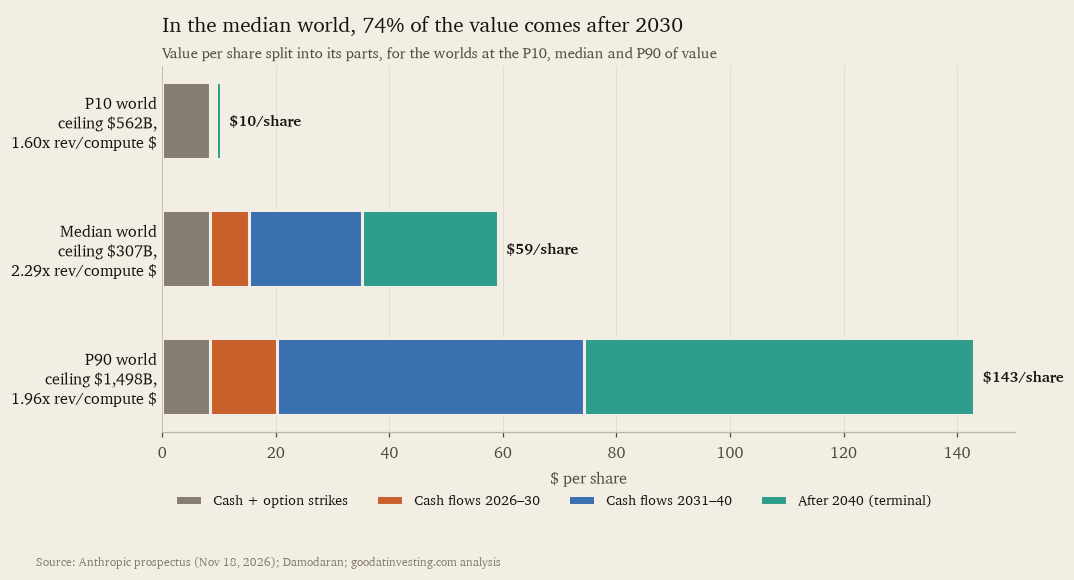

,cash_and_strikes,pv_2026_2030,pv_2031_2040,terminal,total
P10,8.4,0.5,0.7,0.8,10.3
Median,8.4,6.8,20.0,23.9,59.1
P90,8.4,11.8,54.0,68.8,143.0


rev_per_compute,rev/compute low,rev/compute mid,rev/compute high
ceiling,,,
ceiling low,16.1,42.3,60.9
ceiling mid,22.6,67.3,99.2
ceiling high,32.6,108.4,161.5


In [6]:
pick = {p: (val.per_share - val.per_share.quantile(q)).abs().idxmin() for p, q in (('P10', 0.1), ('Median', 0.5), ('P90', 0.9))}
parts = val.loc[list(pick.values()), ['cash_and_strikes', 'pv_2026_2030', 'pv_2031_2040', 'terminal']].set_axis(list(pick), axis=0)
LABEL = {'cash_and_strikes': 'Cash + option strikes', 'pv_2026_2030': 'Cash flows 2026–30',
         'pv_2031_2040': 'Cash flows 2031–40', 'terminal': 'After 2040 (terminal)'}
COL = {'cash_and_strikes': NEUTRAL, 'pv_2026_2030': SERIES[1], 'pv_2031_2040': SERIES[0], 'terminal': SERIES[2]}
ps = parts * 1e6 / fd_shares                                                      # $ per share

fig, ax = plt.subplots(figsize=(10, 5.2))
for i, (world, row) in enumerate(ps.iterrows()):
    pos = neg = 0.0
    for c, v in row.items():
        left = pos if v >= 0 else neg + v
        ax.barh(i, abs(v), left=left, color=COL[c], edgecolor=SURFACE, lw=2, height=0.6,
                label=LABEL[c] if i == 0 else None)
        if v >= 0: pos += v
        else: neg += v
    ax.text(pos + 1.5, i, f'${row.sum():.0f}/share', va='center', fontsize=9.5, fontweight='bold', color=INK)
ax.axvline(0, color=AXIS, lw=1)
ax.set_yticks(range(len(ps)), [f'{w} world\nceiling ${W.ceiling[pick[w]]/B:,.0f}B,\n{W.rev_per_compute[pick[w]]:.2f}x rev/compute $' for w in ps.index])
ax.invert_yaxis()
ax.tick_params(axis='y', length=0, labelcolor=INK)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.set_xlabel('$ per share')
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.13), fontsize=9, ncols=4)
fig.subplots_adjust(bottom=0.24)
share_after_2030 = (parts.pv_2031_2040 + parts.terminal) / parts.sum(axis=1)
ax.set_title(f"In the median world, {share_after_2030['Median']:.0%} of the value comes after 2030")
subtitle(ax, 'Value per share split into its parts, for the worlds at the P10, median and P90 of value')
source(fig, 'Source: Anthropic prospectus (Nov 18, 2026); Damodaran; goodatinvesting.com analysis')
save(fig, '08_value_sources.png')
plt.show()
display(ps.assign(total=ps.sum(axis=1)).round(1))

# Which matters more, the ceiling or the efficiency? Median value per share by thirds of each.
thirds = lambda s, lab: pd.qcut(s, 3, labels=[f'{lab} low', f'{lab} mid', f'{lab} high'])
val.per_share.groupby([thirds(W.ceiling, 'ceiling'), thirds(W.rev_per_compute, 'rev/compute')], observed=True).median().unstack().round(1)

**What this shows** (`08_value_sources.png`): the median world gets little from 2026–2030 (~$7 a share). ~$8 is cash, ~$20 is 2031–2040 and ~$24 is the terminal value. **Buying this stock means buying the 2030s.**
- The **P10 world** has a big ceiling (~$560B) but low efficiency (1.60x revenue per compute dollar). It barely earns above its compute bill, so it's worth about its cash.
- The table under the chart sorts every world into thirds by ceiling and by efficiency. Going across (efficiency) moves value more than going down (ceiling): ~$23 → ~$99 across efficiency at a mid ceiling, ~$42 → ~$108 down the ceiling at mid efficiency. The two forecasts that matter most are **how big the market gets and how cheaply Anthropic can serve it**. Inference cost per dollar of revenue is as much a valuation input as market share.

**Next:** every number above rests on three dials: the discount rate, terminal growth and the 2040 cost structure. How hard does each one push?

## 5. How sensitive is it to the rate, terminal growth and cost structure?
**Method:** re-run the whole valuation (all 20,000 worlds) on a grid and report the **median world's value per share**.
1. **Discount rate × terminal growth.** 9.5% is a low-risk beta of ~1.0; 11.9% is internet-software risk; 13% is extra caution.
2. **Discount rate × 2040 cash opex.** Opex is 25% of revenue in 06, and at ~$1.3T of revenue that's ~$330B a year of sales, people and overhead. Big software companies spread overhead over revenue as they grow, so we also try opex falling in a straight line to 20% or 15% by 2040. Compute efficiency already varies across worlds (1.5–2.5x).

In [7]:
rates = [0.095, r, 0.11, r_high, 0.13]
rate_label = lambda v: f'{v:.1%}' + (' (base)' if v == r else ' (internet β)' if v == r_high else '')
grid_g = pd.DataFrame({f'g = {g:.0%}': [value(rr, g).per_share.median() for rr in rates] for g in (0.02, 0.03, 0.04)},
                      index=[rate_label(v) for v in rates])
late_by_opex = {o: cf_after_2030(o) for o in (0.25, 0.20, 0.15)}
grid_opex = pd.DataFrame({f'opex {o:.0%} by 2040': [value(rr, V['terminal_growth'], cf).per_share.median() for rr in rates]
                          for o, cf in late_by_opex.items()}, index=[rate_label(v) for v in rates])
print('Median value per share, $: discount rate x terminal growth')
display(grid_g.round(1))
print('Median value per share, $: discount rate x 2040 cash opex (g = 3%)')
grid_opex.round(1)

Median value per share, $: discount rate x terminal growth


,g = 2%,g = 3%,g = 4%
9.5%,63.6,68.2,74.4
10.5% (base),55.9,59.1,63.3
11.0%,52.3,54.9,58.2
12.0% (internet β),47.0,48.9,51.2
13.0%,42.3,43.7,45.4


Median value per share, $: discount rate x 2040 cash opex (g = 3%)


,opex 25% by 2040,opex 20% by 2040,opex 15% by 2040
9.5%,68.2,86.6,105.6
10.5% (base),59.1,74.1,89.5
11.0%,54.9,68.3,82.1
12.0% (internet β),48.9,60.0,71.5
13.0%,43.7,52.9,62.4


**What this shows:** 
- **Discount rate:** each percentage point is worth roughly $4–9 a share at the median. 9.5% gives ~$68, 13% ~$44.
- **Terminal growth** moves it less ($56–63 across 2–4%), because everything after 2040 is discounted over 14 years.
- **Cost structure is the big one.** Opex falling to 20% of revenue by 2040 lifts the median to ~$74; 15% gives ~$90. The median world reaches $83 with opex near 17% by 2040, or 20% opex plus a 9.5% rate.

**Next:** turn it around. Given the IPO price, what world is the buyer paying for?

## 6. What is the IPO price betting on?
**Method:** a **reverse DCF**. Instead of asking what the cash flows are worth, ask what cash flows the price requires. Two cuts:
1. **Which worlds clear the IPO price?** Take the worlds worth at least $83 a share, and compare their ceiling, revenue and margins with the rest.
2. **What does the IPO price pay for the median world's cash flows?** That's the return you'd earn if you bought at $83 and the median world happened: the discount rate at which its value equals $83 (its **internal rate of return**).

One cross-check first. The company's own IPO website (an FWP filed with the SEC) gives **~$81B Run-Rate Revenue as of October 2026**. 06's Q4-2026 forecast, which starts from clean Q3 revenue, implies a run-rate of:

In [8]:
q4_run = W['revenue_Q4-2026'] * 4
print(f"06's Q4-2026 run-rate: P10 ${q4_run.quantile(0.1)/B:.0f}B, median ${q4_run.median()/B:.0f}B, P90 ${q4_run.quantile(0.9)/B:.0f}B; "
      f"company's October Run-Rate Revenue ~${x['run_rate_revenue_oct2026']/B:.0f}B (P{(q4_run < x['run_rate_revenue_oct2026']).mean()*100:.0f} of 06)")

mid = ipo_price
clears = val.per_share >= mid
summary = pd.DataFrame({
    'ceiling today, $B': W.ceiling / B, 'revenue 2030, $B': W.revenue_2030 / B, 'revenue 2040, $B': rev_late[2040] / B,
    'rev per compute $': W.rev_per_compute, 'owner FCF margin 2040': margin_2040,
}).groupby(clears.map({True: f'worth ≥ ${mid:.0f} ({clears.mean():.0%})', False: f'worth < ${mid:.0f}'})).median()
display(summary.round(2))

median_world = (val.per_share - val.per_share.median()).abs().idxmin()
rate_grid = np.arange(0.04, 0.16, 0.0005)
ps_at = np.array([value(rr, V['terminal_growth']).per_share[median_world] for rr in rate_grid])
irr_at_mid = np.interp(-mid, -ps_at, rate_grid)          # value falls as the rate rises, so interpolate on -value
print(f'Buying at ${mid:.0f} and getting the median world returns {irr_at_mid:.1%} a year (CAPM asks {r:.1%})')

06's Q4-2026 run-rate: P10 $79B, median $86B, P90 $93B; company's October Run-Rate Revenue ~$81B (P18 of 06)


,"ceiling today, $B","revenue 2030, $B","revenue 2040, $B",rev per compute $,owner FCF margin 2040
per_share,,,,,
worth < $83,441.62,431.03,1015.73,1.85,0.07
worth ≥ $83 (33%),878.05,722.63,1984.86,2.26,0.15


Buying at $83 and getting the median world returns 8.3% a year (CAPM asks 10.5%)


**What this shows:** 
- **The forecast starts on the high side.** The company's own ~$81B October run-rate is at 06's P18: 82% of worlds expect more in Q4. The $81B isn't net of policy-violator revenue, which makes the gap a bit wider. The 30–55% share range implies faster near-term growth than the company has shown so far.
- **The worlds worth ≥ $83 (~33%)** have about twice the ceiling of the rest (~$880B vs ~$440B a year), ~$720B of revenue by 2030, about 2.26x revenue per compute dollar and a ~15% owner FCF margin in 2040. That's the bet the IPO price makes: Anthropic becomes a ~$2T-revenue company by 2040 *and* serves it more cheaply than today.
- **In the median world, $83 earns ~8.3% a year.** That's above Treasuries (4.9%) but short of the ~10.5% stock-market risk asks. A buyer at the IPO price is more optimistic than 06's median, and far more optimistic than Anthropic's own compute contracts (09 §6).

## Findings, by section
1. Discount rate 10.45% = 4.94% + 1.25 × 4.41% (Damodaran rates, ERP and software beta). No debt to blend in. Failure risk is in the cash flows, not the rate.
2. Extending 06's curves to 2040: median revenue ~$1.3T, growing ~7%, at a ~10% owner FCF margin. 3% perpetuity after that.
3. Median value ~$59 a share (~$970B) on 16.4B shares; P10–P90 $10–143. Series G $25.91 is below 80% of worlds, Series H $58.90 at the median, the $70–78 range below ~36–41%, the $83 IPO price below 33%. ~4% of worlds are worth $0: all of them earn under ~$1.57 of revenue per compute dollar, and most have big ceilings. By its own compute contracts, Anthropic is worth ~$18–45 (09 §6).
4. 74% of the median world's value comes after 2030. Efficiency (revenue per compute dollar) moves value more than the ceiling does.
5. Each point of discount rate is worth ~$4–9 a share; terminal growth matters less; opex scaling down to 20% by 2040 gets the median to ~$74, 15% to ~$90.
6. The $83 IPO price needs a top-third world: a ~$880B ceiling and 2.26x efficiency. In the median world it returns ~8.3% a year. The company's ~$81B October run-rate is 06's P18, so the forecast starts high.

**Caveats**
- **The forecast decides the answer.** Everything flows through 06's ceilings, speeds and cost ratios. 06's Anthropic-share range moves it most: 15–35% gave a median of ~$37 (13% of worlds worth $83); 30–55% gives ~$59 (33%); 35–60% gave ~$65 (37%). 06 also never lets opex fall below 25% of revenue, and §5 shows that alone is worth ~$30 a share by 2040.
- **The zero-value worlds are an efficiency story** (§3): a world ~10% less efficient than Q3-2026 loses cash on every extra dollar of revenue, and a bigger market makes it worse.
- **The terminal value is most of it** (§4). It assumes each world's 2040 margin lasts forever, growing at 3%. A world still under its take-or-pay contracts in 2037 is valued off its post-2037 margin.
- **Beta is borrowed.** Listed software averages 1.25, but Anthropic's real sensitivity to the market is unknown until it trades. Concentration on a few partners (Google, Amazon) and on one technology is diversifiable in theory and very much not in practice.
- **No debt, no IPO.** The convertible notes are treated as shares (they convert at the IPO). The IPO's ~800M–980M new shares (plus ~313M in the $26B private placement at $83) and their proceeds are all left out; at a fair price they roughly cancel, at a price above fair value they move value from new buyers to existing holders.
- **Dilution from here on is a cost, not shares.** New grants (4%) and share-paid donations (3%) are charged against cash flow; the Public Benefit Fund's top-ups (up to 2% of shares each time the price rises 50%) aren't in at all. 09 §7 prices both per share: grants and donations take ~$36, the top-ups ~1%.
- **Taxes ignore loss carry-forwards and the deduction for vested stock comp**, so near-term tax is a bit high (as in 03 and 06).
- The IPO terms and $83 price are from the final prospectus (424B4, Nov 18); its financial statements are identical to S-1/A No. 1's, and `01_extract_s1.ipynb` now reads it. The $70–78 range is from S-1/A No. 2.

**Open items:** point `01_extract_s1.ipynb` at S-1/A No. 2 (cached in `source_docs/`) and re-run 01→08; use the ~$81B October run-rate to pin down 06's Q4.

In [9]:
out = pd.concat([val.quantile(PCTS).rename(index=lambda q: f'P{q*100:.0f}'),
                 val.mean().to_frame('mean').T])                # the average world: the post's headline fair value
out = out.rename_axis('percentile').reset_index()
out = out.melt(id_vars='percentile', var_name='metric').assign(
    unit=lambda d: np.where(d.metric == 'per_share', 'usd_per_share', 'millions_usd'),
    discount_rate=r, terminal_growth=V['terminal_growth'])
out.to_csv(DATA / 'valuation.csv', index=False)
print(len(out), 'rows -> data/valuation.csv')

36 rows -> data/valuation.csv
